In [1]:
!nvidia-smi

Thu Nov 19 11:15:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Biomedical Image Analysis · Your project, end to end
### Template notebook · Sessions 13–15 · Thursday 19.11.2026

Prof. Dr. Judith Cerit · SRH University Munich

**How to use it.** Change **only the cell "YOUR DATA"** below. Then run the parts one after the other.
Every part saves what your report needs into the folder `results/`.
In class I run each part first on the demo data (DermaMNIST, skin spots); then you run it on your data.

| Part | Session | What it does | Files in `results/` | Report section |
|---|---|---|---|---|
| A · Data | 13 | look, count, the floor, twins, patients, data table | `A1`–`A4` | 1, 2 |
| B · Models | 14 | a simple baseline, a borrowed network, heat maps | `B1`–`B5` | 3, 6 |
| C · Evaluation | 15 | 3 seeds, an interval, calibration, worst cases | `C1`–`C5` | 4, 5 |

Colab: **Runtime → Change runtime type → T4 GPU** before you start.
Segmentation project (masks)? Use Part A here, and the U-Net cells of the Session 9 notebook for B and C (Dice instead of accuracy).

In [2]:
!wget -q -O /content/ChestXRay2017.zip "https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/f12eaf6d-6023-432f-acc9-80c9d7393433/file_downloaded"
!unzip -q -o /content/ChestXRay2017.zip -d /content/
!ls /content/chest_xray /content/chest_xray/train /content/chest_xray/test
!for d in /content/chest_xray/*/*/; do echo "$d $(ls "$d" | wc -l)"; done

/content/chest_xray:
test  train

/content/chest_xray/test:
NORMAL	PNEUMONIA

/content/chest_xray/train:
NORMAL	PNEUMONIA
/content/chest_xray/test/NORMAL/ 234
/content/chest_xray/test/PNEUMONIA/ 390
/content/chest_xray/train/NORMAL/ 1349
/content/chest_xray/train/PNEUMONIA/ 3883


In [3]:
# import kagglehub
# path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
# !ls {path} {path}/chest_xray

In [4]:
# ============ YOUR DATA: change only this cell ============
import re
QUESTION = "Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage?"
DATA     = "kermany2018"          # only a label here; FOLDER below is what gets loaded
SIZE     = 128                    # ignored for FOLDER (load_folder always uses 128 x 128)
FOLDER   = "/content/chest_xray"  # the folder that contains train/ and test/ (check with !ls)
# FOLDER   = "/root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray"
FOCUS    = "pneumonia"
def PATIENT_ID(name):
    stem = name.rsplit(".", 1)[0]
    if stem.startswith("person"):                       # person12_bacteria_45 -> person12
        return stem.split("_")[0]
    m = re.match(r"(NORMAL2-)?IM-(\d+)-\d+", stem)      # IM-0115-0001 -> IM-0115 ; NORMAL2-IM-1427-0001 -> NORMAL2-IM-1427
    return (m.group(1) or "") + "IM-" + m.group(2) if m else stem
# ===========================================================

In [5]:
# # ============ YOUR DATA: change only this cell ============
# QUESTION = "Can a network find melanoma among skin spots, and how many melanomas does it miss?"
# DATA     = "dermamnist"   # a MedMNIST 2D name: pneumoniamnist, breastmnist, bloodmnist, pathmnist, octmnist, organamnist, ...
# SIZE     = 64             # MedMNIST image size: 28, 64, 128 or 224 (bigger = slower download)
# FOLDER   = None           # OR your own images: a folder with train/ and test/, one subfolder per class inside each
#                           #    e.g. FOLDER = "/content/chest_xray"   (Kermany 2018: train/NORMAL, train/PNEUMONIA, test/...)
# FOCUS    = "melanoma"     # the class your question is about: "pneumonia", "malignant", ...
# PATIENT_ID = None         # optional: how to read the patient from a file name, e.g. for Kermany 2018:
#                           #    PATIENT_ID = lambda name: name.split("_")[0]      ("person12_bacteria_45.jpeg" -> "person12")
# # ===========================================================


## Setup: load the data (no change needed)

In [6]:
import copy, io, os, re, json, zipfile, platform, requests, numpy as np, matplotlib.pyplot as plt, torch
from pathlib import Path
from PIL import Image
from torch import nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

R = Path("results"); R.mkdir(exist_ok=True)
LABELS = {"dermamnist": ["actinic keratosis", "basal cell carcinoma", "benign keratosis", "dermatofibroma", "melanoma", "nevus (mole)", "vascular lesion"],
          "pneumoniamnist": ["normal", "pneumonia"], "breastmnist": ["malignant", "normal or benign"],
          "bloodmnist": ["basophil", "eosinophil", "erythroblast", "immature granulocyte", "lymphocyte", "monocyte", "neutrophil", "platelet"],
          "pathmnist": ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle", "normal colon mucosa", "stroma", "adenocarcinoma"],
          "octmnist": ["choroidal neovascularisation", "diabetic macular oedema", "drusen", "normal"],
          "organamnist": ["bladder", "femur left", "femur right", "heart", "kidney left", "kidney right", "liver", "lung left", "lung right", "pancreas", "spleen"]}
LABELS["organcmnist"] = LABELS["organsmnist"] = LABELS["organamnist"]

def load_medmnist(name, size):
    f = Path("data") / (f"{name}.npz" if size == 28 else f"{name}_{size}.npz"); f.parent.mkdir(exist_ok=True)
    if not f.exists():
        f.write_bytes(requests.get(f"https://zenodo.org/records/10519652/files/{f.name}?download=1", timeout=600).content)
    npz = np.load(f)
    X = {s: npz[f"{s}_images"] for s in ("train", "val", "test")}
    X = {s: np.repeat(x[..., None], 3, -1) if x.ndim == 3 else x for s, x in X.items()}      # grey -> 3 channels
    Y = {s: npz[f"{s}_labels"].ravel() for s in ("train", "val", "test")}
    return X, Y, LABELS.get(name, [str(c) for c in range(int(Y["train"].max()) + 1)]), {s: None for s in X}

def load_folder(root, size=128):
    root = Path(root); classes = sorted(d.name for d in (root / "train").iterdir() if d.is_dir())
    X, Y, N = {}, {}, {}
    for s in ("train", "val", "test"):
        files = [(f, k) for k, c in enumerate(classes) if (root / s / c).exists()
                 for f in sorted((root / s / c).iterdir()) if f.suffix.lower() in (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")]
        if not files: continue
        X[s] = np.stack([np.asarray(Image.open(f).convert("RGB").resize((size, size), Image.BILINEAR)) for f, _ in files])
        Y[s] = np.array([k for _, k in files]); N[s] = [f.name for f, _ in files]
    if "val" not in X or len(Y["val"]) < 50:      # Kermany has only 16 validation images: take 10 % of training instead
        o = np.random.default_rng(0).permutation(len(Y["train"])); v, t = o[:len(o) // 10], o[len(o) // 10:]
        X["val"], Y["val"], N["val"] = X["train"][v], Y["train"][v], [N["train"][i] for i in v]
        X["train"], Y["train"], N["train"] = X["train"][t], Y["train"][t], [N["train"][i] for i in t]
        print("Validation set: 10 % of the training images (random; see the patient check in A4).")
    return X, Y, [c.lower() for c in classes], N

X, Y, CLASSES, NAMES = load_folder(FOLDER) if FOLDER else load_medmnist(DATA, SIZE)
F_ = CLASSES.index(FOCUS.lower())       # number of the focus class
for s in ("train", "val", "test"):
    print(f"{s:5s} {len(Y[s]):6d} images of {X[s].shape[1]} × {X[s].shape[2]} pixels")
print("classes:", ", ".join(CLASSES), "   focus:", CLASSES[F_])

Validation set: 10 % of the training images (random; see the patient check in A4).
train   4709 images of 128 × 128 pixels
val      523 images of 128 × 128 pixels
test     624 images of 128 × 128 pixels
classes: normal, pneumonia    focus: pneumonia


---
# Part A · Data (Session 13) → report sections 1 and 2
## A1 · Look at 20 images, with their labels

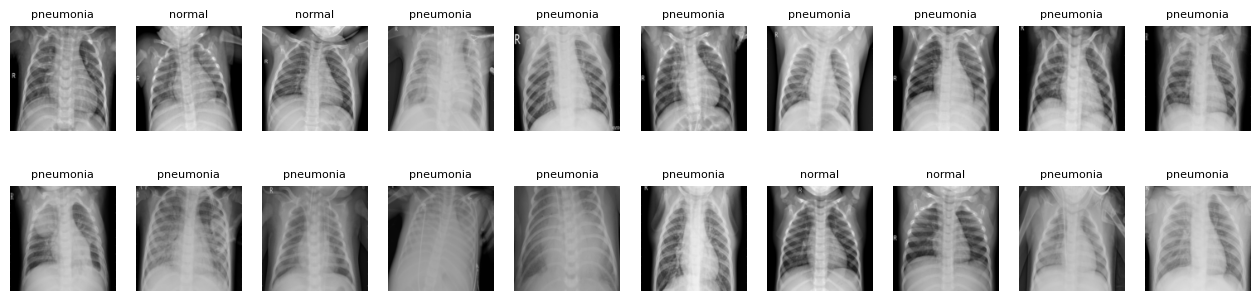

In [7]:
rng = np.random.default_rng(1)
pick = rng.choice(len(Y["train"]), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(X["train"][i]); ax.set_title(CLASSES[Y["train"][i]][:18], fontsize=8); ax.axis("off")
fig.savefig(R / "A1_examples.png", dpi=150, bbox_inches="tight"); plt.show()

## A2 · Count: images per class, and the floor

In [8]:
counts = {s: np.bincount(Y[s], minlength=len(CLASSES)) for s in ("train", "val", "test")}
lines = ["class," + ",".join(counts)]
for k, c in enumerate(CLASSES):
    lines.append(f"{c}," + ",".join(str(counts[s][k]) for s in counts))
    print(f"{c:28s} " + "  ".join(f"{counts[s][k]:6d}" for s in counts) + f"   {counts['train'][k] / counts['train'].sum():6.1%} of training")
(R / "A2_counts.csv").write_text("\n".join(lines))
majority = int(np.argmax(counts["train"]))
floor = float(np.mean(Y["test"] == majority))
floor_focus = 1.0 if majority == F_ else 0.0
print(f"\nThe floor: always say '{CLASSES[majority]}' -> {floor:.1%} of the test images right,"
      f" and {floor_focus:.0%} of the '{CLASSES[F_]}' images found.")

normal                         1218     131     234    25.9% of training
pneumonia                      3491     392     390    74.1% of training

The floor: always say 'pneumonia' -> 62.5% of the test images right, and 100% of the 'pneumonia' images found.


## A3 · Twins: is (almost) the same image in training and in test?
For every test image: its most similar training image (mean pixel difference, at 64 × 64).

In [9]:
def small(x):
    t = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    return F.interpolate(t, size=(64, 64), mode="bilinear", antialias=True).reshape(len(t), -1)
tr, te = small(X["train"]), small(X["test"])
dist, nearest = torch.cat([torch.cdist(te[i:i + 500], tr) for i in range(0, len(te), 500)]).div(tr.shape[1] ** 0.5).min(1)
twins = (dist < 0.03).nonzero().ravel()
print(f"{len(twins)} of {len(te)} test images have an almost identical training image (difference < 0.03).")
order = twins[dist[twins].argsort()][:6]
if len(order):
    fig, axes = plt.subplots(2, len(order), figsize=(2 * len(order), 4.2), squeeze=False)
    for k, t in enumerate(order):
        axes[0, k].imshow(X["test"][t]); axes[0, k].set_title("test", fontsize=9)
        axes[1, k].imshow(X["train"][nearest[t]]); axes[1, k].set_title("training", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    fig.savefig(R / "A3_twins.png", dpi=150, bbox_inches="tight"); plt.show()

0 of 624 test images have an almost identical training image (difference < 0.03).


## A4 · Patients: is the same patient in training and in test?
Only possible if the file names (or a table) tell the patient. MedMNIST does not: then write that in the report.

In [10]:
if PATIENT_ID and NAMES["train"]:
    P = {s: {PATIENT_ID(n) for n in NAMES[s]} for s in NAMES}
    both = P["train"] & P["test"]
    print(f"patients: training {len(P['train'])}, test {len(P['test'])}, in both {len(both)}")
    leak_val = P["train"] & P["val"]
    print(f"patients in training and validation: {len(leak_val)}")
    patient_line = f"{len(P['train'])} training / {len(P['test'])} test patients; {len(both)} in both"
else:
    patient_line = "patient not known from the files: cannot check (say so in the report)"
    print(patient_line)

patients: training 2685, test 427, in both 161
patients in training and validation: 297


## A5 · The data table (report, section 2)
The numbers are filled in for you. Complete the lines with `…` by hand in `results/A5_data_table.md`.

In [11]:
n_all = sum(len(Y[s]) for s in Y)
table = f"""| | |
|---|---|
| Question | {QUESTION} |
| Source, licence | … (name, link, licence) |
| Modality, size | … ; {n_all} images, used at {X['train'].shape[1]} × {X['train'].shape[2]} pixels |
| Labels | {len(CLASSES)} classes: {', '.join(CLASSES)}; who decided them: … |
| Classes | largest: {CLASSES[majority]} {counts['train'][majority] / counts['train'].sum():.0%} of training; focus: {CLASSES[F_]} {counts['train'][F_] / counts['train'].sum():.0%}; floor {floor:.1%} |
| Splits | {len(Y['train'])} / {len(Y['val'])} / {len(Y['test'])} (training / validation / test) |
| Quality checks | {len(twins)} of {len(te)} test images have a near-twin in training; {patient_line} |
| Where my data could differ | site: … · device: … · population: … · who labelled: … |
| A possible shortcut | … |
"""
(R / "A5_data_table.md").write_text(table); print(table)

| | |
|---|---|
| Question | Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage? |
| Source, licence | … (name, link, licence) |
| Modality, size | … ; 5856 images, used at 128 × 128 pixels |
| Labels | 2 classes: normal, pneumonia; who decided them: … |
| Classes | largest: pneumonia 74% of training; focus: pneumonia 74%; floor 62.5% |
| Splits | 4709 / 523 / 624 (training / validation / test) |
| Quality checks | 0 of 624 test images have a near-twin in training; 2685 training / 427 test patients; 161 in both |
| Where my data could differ | site: … · device: … · population: … · who labelled: … |
| A possible shortcut | … |



### Before you go on: push Part A
GitHub: your repository → **Add file → Upload files** → the `results/` folder.
Then in Colab: **File → Save a copy in GitHub** (the notebook with its outputs).

---
# Part B · Models (Session 14) → report sections 3 and 6
## B1 · A simple baseline: colour and brightness features + a random forest
No deep learning: 48 colour-histogram values + an 8 × 8 thumbnail per image.

In [12]:
def handmade(x):
    hist = np.stack([np.concatenate([np.histogram(im[..., c], bins=16, range=(0, 255))[0] for c in range(3)]) for im in x]) / (x.shape[1] * x.shape[2])
    thumb = F.adaptive_avg_pool2d(torch.tensor(x, dtype=torch.float32).mean(-1)[:, None], 8).reshape(len(x), -1).numpy() / 255
    return np.hstack([hist, thumb])
rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(handmade(X["train"]), Y["train"])
pred_rf = rf.predict(handmade(X["test"]))
def score(pred, y=None):
    y = Y["test"] if y is None else y
    return float(np.mean(pred == y)), float(np.mean(pred[y == F_] == F_))
acc_rf, focus_rf = score(pred_rf)
print(f"baseline (random forest): accuracy {acc_rf:.1%}, {CLASSES[F_]} found {focus_rf:.1%}")

baseline (random forest): accuracy 76.9%, pneumonia found 98.5%


## B2 · A borrowed network: ResNet-18 trained on photos, frozen; only a new last layer learns (Session 7)
Images are enlarged to 224 × 224. The frozen network turns every image into 512 numbers once; then the last layer learns in seconds.
Two versions: plain, and **balanced** (mistakes on rare classes count more: Session 13).

network, plain   : accuracy 82.4%, pneumonia found 98.5%
network, balanced: accuracy 85.6%, pneumonia found 97.7%


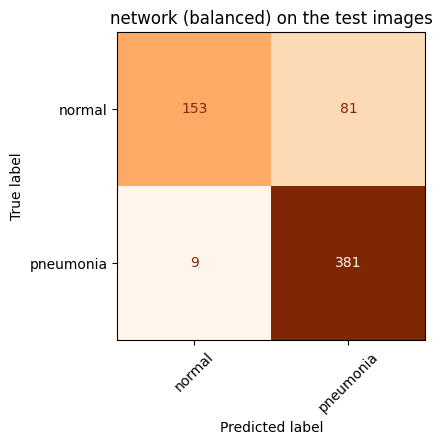

In [13]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def prep(x):
    t = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    return (F.interpolate(t, size=(224, 224), mode="bilinear") - MEAN) / STD
net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).eval().to(device)
body = nn.Sequential(*list(net.children())[:-1])              # everything except the last layer
with torch.no_grad():
    FEAT = {s: torch.cat([body(prep(X[s][i:i + 128]).to(device)).flatten(1).cpu() for i in range(0, len(X[s]), 128)]) for s in X}

def train_head(seed=0, balanced=False, epochs=10):
    torch.manual_seed(seed)
    head = nn.Linear(512, len(CLASSES)); opt = torch.optim.Adam(head.parameters(), lr=1e-3)
    w = torch.tensor(len(Y["train"]) / (len(CLASSES) * np.maximum(counts["train"], 1)), dtype=torch.float32) if balanced else None
    x, y = FEAT["train"], torch.tensor(Y["train"]).long()
    for _ in range(epochs):
        o = torch.randperm(len(y))
        for i in range(0, len(o), 64):
            b = o[i:i + 64]; loss = F.cross_entropy(head(x[b]), y[b], weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
    return head.eval()
def probs(head, s="test"):
    with torch.no_grad(): return F.softmax(head(FEAT[s]), 1).numpy()

heads = {"plain": train_head(0), "balanced": train_head(0, balanced=True)}
for k, h in heads.items():
    a, f = score(probs(h).argmax(1)); print(f"network, {k:8s}: accuracy {a:.1%}, {CLASSES[F_]} found {f:.1%}")
USE = "balanced"      # the version used from here on (change to "plain" if that answers your question better)
head = heads[USE]; P_test = probs(head); pred = P_test.argmax(1); acc, focus = score(pred)
fig, ax = plt.subplots(figsize=(1.0 * len(CLASSES) + 3, 1.0 * len(CLASSES) + 2))
ConfusionMatrixDisplay(confusion_matrix(Y["test"], pred), display_labels=[c[:14] for c in CLASSES]).plot(ax=ax, cmap="Oranges", colorbar=False, xticks_rotation=45)
ax.set_title(f"network ({USE}) on the test images"); fig.savefig(R / "B2_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

## B3 · Your numbers side by side (report, section 5)

In [14]:
numbers = f"""| model | accuracy | {CLASSES[F_]} found |
|---|---|---|
| floor: always '{CLASSES[majority]}' | {floor:.1%} | {floor_focus:.0%} |
| random forest on colour features | {acc_rf:.1%} | {focus_rf:.1%} |
| ResNet-18 frozen, plain | {score(probs(heads['plain']).argmax(1))[0]:.1%} | {score(probs(heads['plain']).argmax(1))[1]:.1%} |
| ResNet-18 frozen, balanced | {score(probs(heads['balanced']).argmax(1))[0]:.1%} | {score(probs(heads['balanced']).argmax(1))[1]:.1%} |
"""
(R / "B3_numbers.md").write_text(numbers); print(numbers)

| model | accuracy | pneumonia found |
|---|---|---|
| floor: always 'pneumonia' | 62.5% | 100% |
| random forest on colour features | 76.9% | 98.5% |
| ResNet-18 frozen, plain | 82.4% | 98.5% |
| ResNet-18 frozen, balanced | 85.6% | 97.7% |



## B4 · What does it look at? Grad-CAM heat maps for 8 test images
Rows: found (the focus class, called right) · missed (focus class, called something else) · false alarms (called focus class, but it is not).

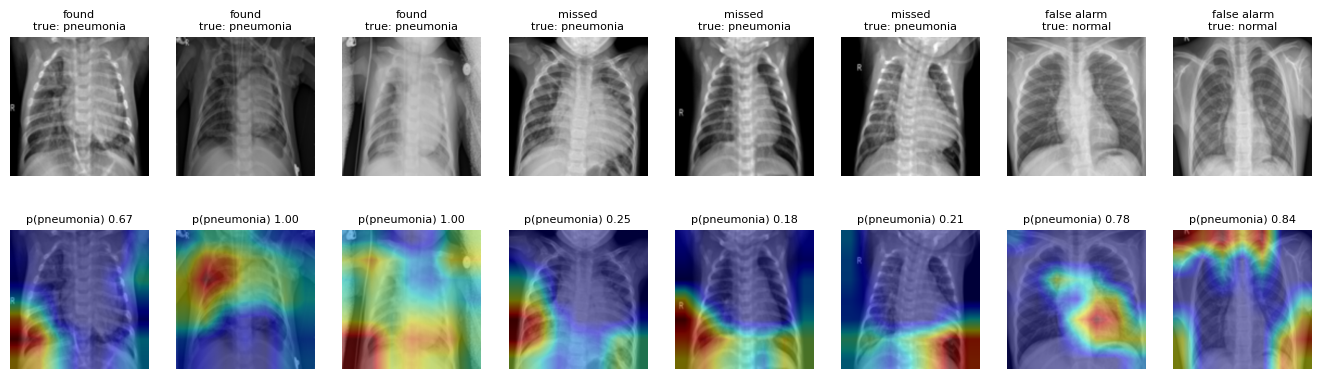

In [15]:
full = nn.Sequential(body, nn.Flatten(), copy.deepcopy(head).to(device)).eval()
def gradcam(model, x, cls):
    acts = {}
    h = model[0][7].register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))      # model[0][7] = layer4, the last conv block
    x = x.to(device).requires_grad_(True); out = model(x)
    g = torch.autograd.grad(out[range(len(cls)), cls].sum(), acts["a"])[0]; h.remove()
    cam = F.relu((g.mean((2, 3), keepdim=True) * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear")[:, 0]
    return (cam / (cam.amax((1, 2), keepdim=True) + 1e-8)).detach().cpu().numpy()
y = Y["test"]
groups = {"found": np.where((y == F_) & (pred == F_))[0][:3], "missed": np.where((y == F_) & (pred != F_))[0][:3],
          "false alarm": np.where((y != F_) & (pred == F_))[0][:2]}
show = [(g, i) for g, idx in groups.items() for i in idx]
cams = gradcam(full, prep(X["test"][[i for _, i in show]]), torch.full((len(show),), F_))
fig, axes = plt.subplots(2, len(show), figsize=(2.1 * len(show), 4.6), squeeze=False)
for k, ((g, i), c) in enumerate(zip(show, cams)):
    big = np.asarray(Image.fromarray(X["test"][i]).resize((224, 224)))
    axes[0, k].imshow(big); axes[0, k].set_title(f"{g}\ntrue: {CLASSES[y[i]][:12]}", fontsize=8)
    axes[1, k].imshow(big); axes[1, k].imshow(c, cmap="jet", alpha=0.45); axes[1, k].set_title(f"p({CLASSES[F_][:10]}) {P_test[i, F_]:.2f}", fontsize=8)
for a in axes.ravel(): a.axis("off")
fig.savefig(R / "B4_gradcam.png", dpi=150, bbox_inches="tight"); plt.show()

## B5 · Sanity check: do the heat maps depend on what the network learned?
Same images, but the last layer (the only part that learned YOUR classes) gets **random** weights again.
If the maps look the same, they do not show what the network learned about your classes.

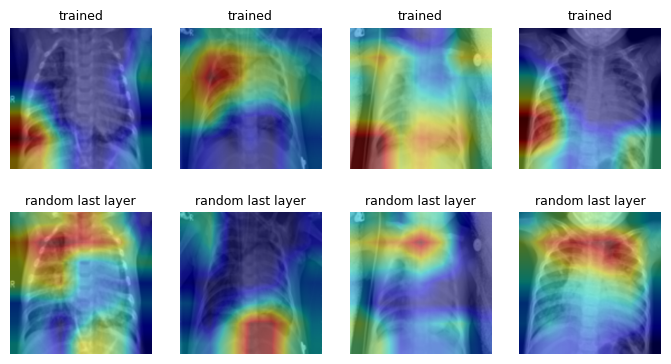

similarity trained vs random maps (correlation, 1 = identical): -0.48 -0.59 -0.05 -0.57 -0.49 -0.38 -0.40 -0.00


In [16]:
torch.manual_seed(1); rand_head = nn.Linear(512, len(CLASSES))
rand_full = nn.Sequential(body, nn.Flatten(), rand_head.to(device)).eval()
cams_r = gradcam(rand_full, prep(X["test"][[i for _, i in show]]), torch.full((len(show),), F_))
same = [float(np.corrcoef(a.ravel(), b.ravel())[0, 1]) if a.std() > 0 and b.std() > 0 else float("nan") for a, b in zip(cams, cams_r)]
fig, axes = plt.subplots(2, 4, figsize=(8.4, 4.4))
for k in range(4):
    big = np.asarray(Image.fromarray(X["test"][show[k][1]]).resize((224, 224)))
    for r, (c, t) in enumerate([(cams[k], "trained"), (cams_r[k], "random last layer")]):
        axes[r, k].imshow(big); axes[r, k].imshow(c, cmap="jet", alpha=0.45); axes[r, k].set_title(t, fontsize=9); axes[r, k].axis("off")
fig.savefig(R / "B5_sanity.png", dpi=150, bbox_inches="tight"); plt.show()
print("similarity trained vs random maps (correlation, 1 = identical):", " ".join(f"{s:.2f}" for s in same))

### Before you go on: push Part B
Upload `results/` again and **File → Save a copy in GitHub**.
README: one heat map you would show, one you would not trust, and why (report, section 6).

---
# Part C · Evaluation (Session 15) → report sections 4 and 5
## C1 · Three seeds: how much does the number move if we train again?

In [17]:
seed_res = [score(probs(train_head(s, balanced=(USE == "balanced"))).argmax(1)) for s in (0, 1, 2)]
sa, sf = np.array(seed_res).T
print(f"accuracy {sa.mean():.1%} ± {sa.std(ddof=1):.1%}   {CLASSES[F_]} found {sf.mean():.1%} ± {sf.std(ddof=1):.1%}   (3 seeds)")
(R / "C1_seeds.json").write_text(json.dumps({"accuracy": sa.tolist(), "focus_found": sf.tolist()}))

accuracy 84.9% ± 0.9%   pneumonia found 97.8% ± 0.4%   (3 seeds)


150

## C2 · The bootstrap: how sure are we of the number on THIS test set?
Draw the test set again 2 000 times, with replacement (like re-doing the poll with other people); look at the spread.

accuracy 85.6%  (95 % interval 82.9% to 88.3%)
pneumonia found 381 of 390 = 97.7%  (95 % interval 96.1% to 99.0%)


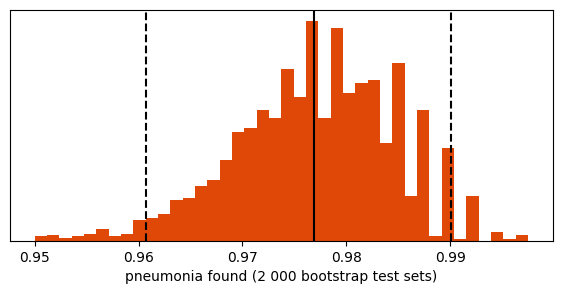

In [18]:
rng = np.random.default_rng(0); B = 2000; n = len(y); boot_acc, boot_f = [], []
for _ in range(B):
    i = rng.integers(0, n, n); boot_acc.append(np.mean(pred[i] == y[i])); m = y[i] == F_; boot_f.append(np.mean(pred[i][m] == F_))
ci_acc, ci_f = np.percentile(boot_acc, [2.5, 97.5]), np.percentile(boot_f, [2.5, 97.5])
n_f = int((y == F_).sum()); k_f = int(((y == F_) & (pred == F_)).sum())
print(f"accuracy {acc:.1%}  (95 % interval {ci_acc[0]:.1%} to {ci_acc[1]:.1%})")
print(f"{CLASSES[F_]} found {k_f} of {n_f} = {focus:.1%}  (95 % interval {ci_f[0]:.1%} to {ci_f[1]:.1%})")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(boot_f, bins=40, color="#DF4807"); ax.axvline(focus, color="k")
for v in ci_f: ax.axvline(v, color="k", ls="--")
ax.set_xlabel(f"{CLASSES[F_]} found (2 000 bootstrap test sets)"); ax.set_yticks([])
fig.savefig(R / "C2_bootstrap.png", dpi=150, bbox_inches="tight"); plt.show()

## C3 · Calibration: when the network says 70 %, is it right 7 times in 10?
For the focus class: group the test images by the predicted probability, compare with how often it really was the focus class.

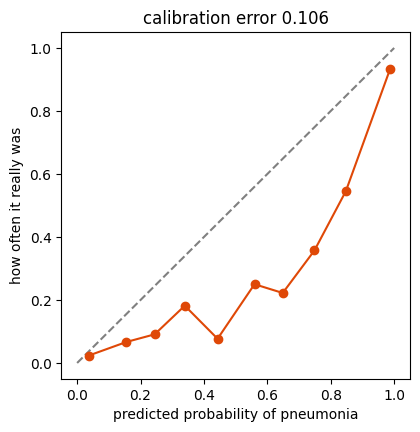

calibration error (ECE) for 'pneumonia': 0.106   (0 = the probabilities can be taken at their word)


In [19]:
p = P_test[:, F_]; truth = (y == F_).astype(float); bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
mean_p = np.array([p[idx == b].mean() if (idx == b).any() else np.nan for b in range(10)])
frac = np.array([truth[idx == b].mean() if (idx == b).any() else np.nan for b in range(10)])
nb = np.array([(idx == b).sum() for b in range(10)])
ece = float(np.nansum(nb * np.abs(mean_p - frac)) / n)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey"); ax.plot(mean_p, frac, "o-", color="#DF4807")
ax.set_xlabel(f"predicted probability of {CLASSES[F_]}"); ax.set_ylabel("how often it really was"); ax.set_title(f"calibration error {ece:.3f}")
fig.savefig(R / "C3_calibration.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"calibration error (ECE) for '{CLASSES[F_]}': {ece:.3f}   (0 = the probabilities can be taken at their word)")

## C4 · The worst cases: the 8 most confident mistakes

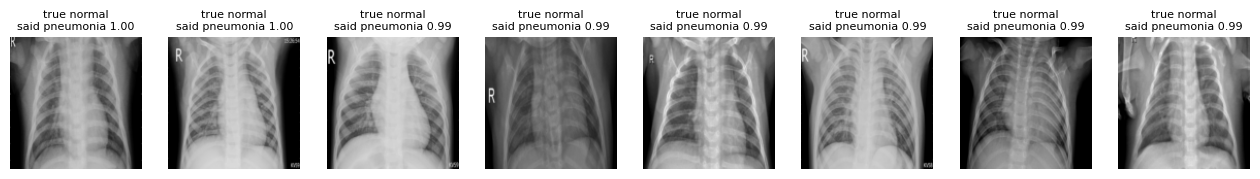

In [20]:
wrong = np.where(pred != y)[0]; worst = wrong[np.argsort(-P_test[wrong, pred[wrong]])][:8]
fig, axes = plt.subplots(1, len(worst), figsize=(2 * len(worst), 2.6), squeeze=False)
for a, i in zip(axes[0], worst):
    a.imshow(X["test"][i]); a.set_title(f"true {CLASSES[y[i]][:11]}\nsaid {CLASSES[pred[i]][:11]} {P_test[i, pred[i]]:.2f}", fontsize=8); a.axis("off")
fig.savefig(R / "C4_worst.png", dpi=150, bbox_inches="tight"); plt.show()

## C5 · Your result in sentences (report, sections 4 and 5), and the files for running it again

In [21]:
summary = f"""Question: {QUESTION}
On {n} test images, the frozen ResNet-18 ({USE}) found {k_f} of {n_f} {CLASSES[F_]} images ({focus:.1%}; 95 % bootstrap interval {ci_f[0]:.1%} to {ci_f[1]:.1%}).
Accuracy {acc:.1%} (interval {ci_acc[0]:.1%} to {ci_acc[1]:.1%}); floor {floor:.1%}; random-forest baseline {acc_rf:.1%}.
Three training seeds: {CLASSES[F_]} found {sf.mean():.1%} ± {sf.std(ddof=1):.1%}. Calibration error for {CLASSES[F_]}: {ece:.3f}.
Limits: one data set, test images from the same source (internal validation only); {len(twins)} near-twins between training and test; {patient_line}.
"""
(R / "C5_summary.md").write_text(summary); print(summary)
import sklearn, torchvision
Path("requirements.txt").write_text(f"numpy=={np.__version__}\ntorch=={torch.__version__.split('+')[0]}\ntorchvision=={torchvision.__version__.split('+')[0]}\n"
                                    f"scikit-learn=={sklearn.__version__}\nmatplotlib\nPillow\nrequests\n")
print(Path("requirements.txt").read_text())
print("README · How to run: open the notebook in Google Colab (T4 GPU), set the YOUR DATA cell, Runtime → Run all (about 3 minutes).")

Question: Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage?
On 624 test images, the frozen ResNet-18 (balanced) found 381 of 390 pneumonia images (97.7%; 95 % bootstrap interval 96.1% to 99.0%).
Accuracy 85.6% (interval 82.9% to 88.3%); floor 62.5%; random-forest baseline 76.9%.
Three training seeds: pneumonia found 97.8% ± 0.4%. Calibration error for pneumonia: 0.106.
Limits: one data set, test images from the same source (internal validation only); 0 near-twins between training and test; 2685 training / 427 test patients; 161 in both.

numpy==2.4.6
torch==2.14.1
torchvision==0.29.1
scikit-learn==1.6.1
matplotlib
Pillow
requests

README · How to run: open the notebook in Google Colab (T4 GPU), set the YOUR DATA cell, Runtime → Run all (about 3 minutes).


### Last step: download everything and push
The cell below makes `results.zip` (in Colab it downloads). Upload `results/`, `requirements.txt` and the notebook to your repository.

In [22]:
with zipfile.ZipFile("results.zip", "w") as z:
    for f in sorted(R.iterdir()): z.write(f)
    z.write("requirements.txt")
try:
    from google.colab import files; files.download("results.zip")
except ImportError:
    print("results.zip written:", sorted(f.name for f in R.iterdir()))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>